In [98]:
import pandas as pd
import matplotlib.pyplot as plt

COLS = ["group", "mean", "hdi_2.5%", "hdi_97.5%", "E[rank]", "metric", "Pr_sup"]

raw_data = pd.read_csv('./out/Table_1_data.csv', sep=";")
useful_variables = raw_data[COLS]

df = useful_variables#[useful_variables['metric'] == 'IoU']

metrics=df['metric'].unique()
print(metrics)
display(df)

<StringArray>
['IoU', 'Dice', 'NSD', 'epistemic', 'aleatoric']
Length: 5, dtype: str


,group,mean,hdi_2.5%,hdi_97.5%,E[rank],metric,Pr_sup
0,U-Net | AE,0.798,0.784,0.810,1.009,IoU,0.9910
1,Swin U-Net | AE,0.764,0.739,0.792,2.176,IoU,0.8149
2,Terramind | AE,0.753,0.747,0.759,2.815,IoU,1.0000
3,U-Net | PS,0.641,0.615,0.663,4.005,IoU,0.9950
4,Swin U-Net | PS,0.600,0.585,0.616,4.996,IoU,0.9990
5,Terramind | PS,0.568,0.564,0.573,6.006,IoU,0.9929
6,Swin U-Net | S2,0.548,0.535,0.564,6.993,IoU,1.0000
7,Terramind | S2,0.415,0.404,0.426,8.000,IoU,1.0000
8,U-Net | S2,0.127,0.114,0.140,9.000,IoU,NaN
9,U-Net | AE,0.887,0.880,0.896,1.011,Dice,0.9894


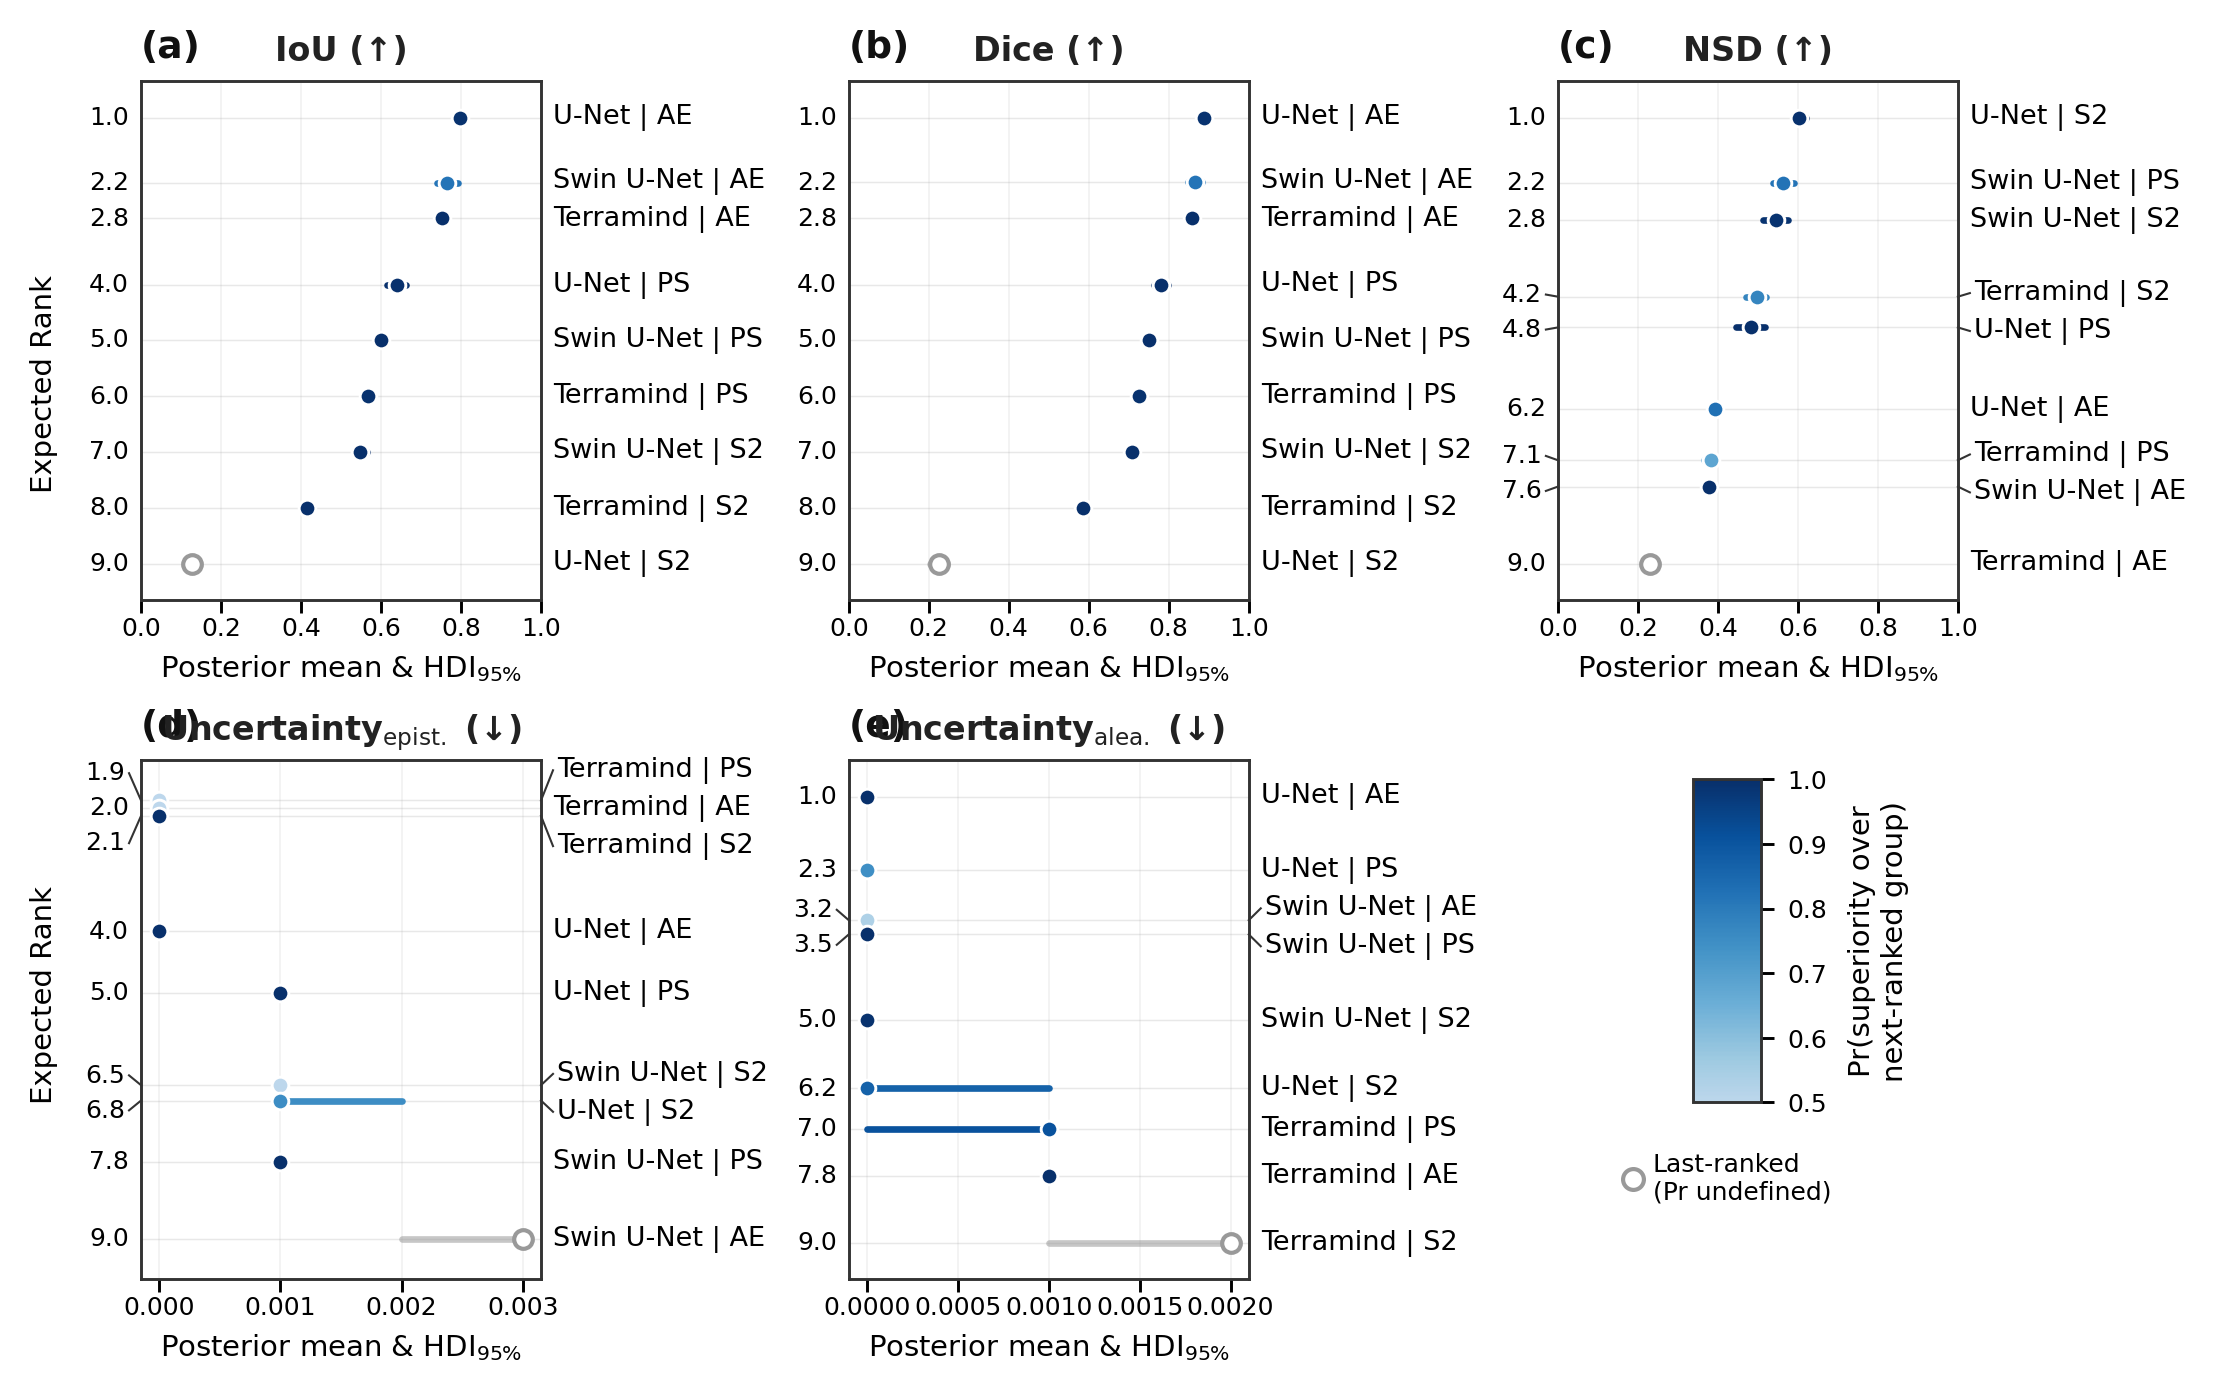

In [ ]:
"""
Figure replacing Table 1: Posterior performance, expected rank, and
probability of superiority over next-ranked group for each
sensor–architecture combination across five evaluation metrics.

Changes in this version
────────────────────────
1. Panel labels (a)–(e): placed ABOVE the axes frame, flush-left (outside)
2. Colormap: truncated single-hue Blues — light (uncertain, 0.5) → dark (certain, 1.0)
3. Colorbar + legend: cleanly separated into upper / lower regions of the
   empty 6th slot, with the legend as a dedicated axis so it never overlaps
   the colorbar or its label
"""

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.transforms import blended_transform_factory
from matplotlib.lines import Line2D

# ── Publication rcParams ──────────────────────────────────────────────────────
mpl.rcParams.update({
    "font.size":          7,
    "axes.titlesize":     8,
    "axes.labelsize":     7,
    "xtick.labelsize":    6,
    "ytick.labelsize":    6.5,
    "axes.linewidth":     0.7,
    "xtick.major.width":  0.7,
    "ytick.major.width":  0.7,
    "xtick.major.size":   3,
    "ytick.major.size":   3,
    "pdf.fonttype":       42,
    "ps.fonttype":        42,
    "figure.facecolor":   "white",
    "axes.facecolor":     "white",
})

# ── Load data ─────────────────────────────────────────────────────────────────
COLS = ["group", "mean", "hdi_2.5%", "hdi_97.5%", "E[rank]", "metric", "Pr_sup"]
df = pd.read_csv('./out/Table_1_data.csv', sep=";")[COLS]

# ── Constants ─────────────────────────────────────────────────────────────────
metrics_to_plot = ['IoU', 'Dice', 'NSD', 'epistemic', 'aleatoric']

METRIC_HEADINGS = {
    'IoU':       'IoU (↑)',
    'Dice':      'Dice (↑)',
    'NSD':       'NSD (↑)',
    'epistemic': r'Uncertainty$_\mathrm{epist.}$ (↓)',
    'aleatoric': r'Uncertainty$_\mathrm{alea.}$ (↓)',
}
PANEL_LABELS        = ['(a)', '(b)', '(c)', '(d)', '(e)']
UNCERTAINTY_METRICS = {'epistemic', 'aleatoric'}
SPINE_COLOR         = "#333333"

# Probability of superiority: fixed theoretical range [0.5, 1.0]
PR_VMIN, PR_VMAX = 0.5, 1.0
LAST_RANK_COLOR  = "#999999"   # undefined (last-ranked) group

# ── Colormap ──────────────────────────────────────────────────────────────────
# Truncated Blues: skip the near-white bottom quarter so even Pr=0.5 is
# visibly blue and separable from the white plot background.
_base   = mpl.colormaps['Blues']
pr_cmap = mpl.colors.LinearSegmentedColormap.from_list(
    'pr_sup', [_base(v) for v in np.linspace(0.28, 1.0, 256)], N=256
)
pr_norm = mpl.colors.Normalize(vmin=PR_VMIN, vmax=PR_VMAX)

# ── Figure geometry ───────────────────────────────────────────────────────────
FIG_W_CM    = 18.0
ITEM_H_CM   = 0.55
MIN_PANEL_H = 2.5

def panel_height(n_items):
    return max(MIN_PANEL_H, n_items * ITEM_H_CM)

n_items_row0 = max(len(df[df['metric'] == m]) for m in metrics_to_plot[:3])
n_items_row1 = max(len(df[df['metric'] == m]) for m in metrics_to_plot[3:])
PLOT_W_CM    = (FIG_W_CM - 1.8) / 3

h_row = [
    max(panel_height(n_items_row0), PLOT_W_CM / 2.0),
    max(panel_height(n_items_row1), PLOT_W_CM / 2.0),
]

FIG_H_CM = sum(h_row) + 0.6 + 0.5 + 0.5

# ── Callout helpers ───────────────────────────────────────────────────────────
def spread_y_positions(y_data, min_gap):
    """Push overlapping label positions apart while preserving order."""
    pairs   = sorted(enumerate(y_data), key=lambda p: p[1])
    indices = [p[0] for p in pairs]
    pos     = [p[1] for p in pairs]
    for _ in range(500):
        moved = False
        for i in range(1, len(pos)):
            if pos[i] - pos[i - 1] < min_gap:
                mid         = (pos[i] + pos[i - 1]) / 2.0
                pos[i - 1] = mid - min_gap / 2.0
                pos[i]     = mid + min_gap / 2.0
                moved = True
        if not moved:
            break
    result = [0.0] * len(y_data)
    for sort_i, orig_i in enumerate(indices):
        result[orig_i] = pos[sort_i]
    return result


def apply_side_callouts(ax, y_data, labels, fig_dpi, fontsize=6.5, side='left', color='#222222'):
    ax_h_in   = ax.get_window_extent().height / fig_dpi
    y_range   = abs(ax.get_ylim()[1] - ax.get_ylim()[0])
    line_h_in = fontsize * 1.4 / 72.0
    gap       = (line_h_in / ax_h_in) * y_range if ax_h_in > 0 else 0.5

    y_spread = spread_y_positions(list(y_data), gap)
    trans    = blended_transform_factory(ax.transAxes, ax.transData)

    if side == 'left':
        x0, x1              = 0.0,   -0.03
        xt_moved, xt_nomove = -0.04, -0.03
        ha = 'right'
    else:
        x0, x1              = 1.0,   1.03
        xt_moved, xt_nomove =  1.04,  1.03
        ha = 'left'

    for y_act, y_lbl, label in zip(y_data, y_spread, labels):
        moved = abs(y_act - y_lbl) > gap * 0.05
        if moved:
            ax.plot([x0, x1], [y_act, y_lbl],
                    color='#333333', lw=0.5, clip_on=False,
                    transform=trans, zorder=5)
        ax.text(xt_moved if moved else xt_nomove, y_lbl, label,
                ha=ha, va='center', fontsize=fontsize, color=color,
                transform=trans, clip_on=False)


# ── Build figure ──────────────────────────────────────────────────────────────
fig = plt.figure(
    figsize=(FIG_W_CM / 2.54, FIG_H_CM / 2.54),
    dpi=300,
    constrained_layout=True,
)
gs = GridSpec(2, 6, figure=fig, height_ratios=[h_row[0], h_row[1]])

ax_slots = [
    fig.add_subplot(gs[0, 0:2]),
    fig.add_subplot(gs[0, 2:4]),
    fig.add_subplot(gs[0, 4:6]),
    fig.add_subplot(gs[1, 0:2]),
    fig.add_subplot(gs[1, 2:4]),
]

axes_callout_data = []

for col_idx, (ax, metric) in enumerate(zip(ax_slots, metrics_to_plot)):
    df_m    = df[df['metric'] == metric].sort_values('E[rank]').copy()
    x       = df_m['mean'].values
    y       = df_m['E[rank]'].values
    pr_vals = df_m['Pr_sup'].values
    n       = len(df_m)

    for spine in ['top', 'right', 'left', 'bottom']:
        ax.spines[spine].set_linewidth(0.7)
        ax.spines[spine].set_color(SPINE_COLOR)

    for yp in y:
        ax.axhline(yp, color="#E8E8E8", linewidth=0.35, zorder=0)

    # HDI bars coloured by Pr_sup
    for i in range(n):
        pr_val    = pr_vals[i]
        is_nan    = np.isnan(pr_val)
        bar_color = LAST_RANK_COLOR if is_nan else pr_cmap(pr_norm(pr_val))
        bar_alpha = 0.55 if is_nan else 1.0
        lc = ax.hlines(
            y     = df_m['E[rank]'].iloc[i],
            xmin  = df_m['hdi_2.5%'].iloc[i],
            xmax  = df_m['hdi_97.5%'].iloc[i],
            color = bar_color,
            lw    = 1.6,
            alpha = bar_alpha,
            zorder= 2,
        )
        lc.set_capstyle('round')

    # Mean dots: open grey circle for last-ranked, coloured fill for others
    for i in range(n):
        pr_val = pr_vals[i]
        if np.isnan(pr_val):
            ax.scatter(x[i], y[i], s=15, marker='o',
                       facecolors='white', edgecolors=LAST_RANK_COLOR,
                       linewidths=1.0, zorder=4)
        else:
            ax.scatter(x[i], y[i], s=10, marker='o',
                       c=[pr_val], cmap=pr_cmap, norm=pr_norm,
                       edgecolors='white', linewidths=0.7, zorder=3)

    ax.grid(axis='x', alpha=0.18, linewidth=0.4, zorder=0)
    ax.set_axisbelow(True)
    ax.set_yticks(y.tolist())
    ax.set_yticklabels([])
    ax.tick_params(axis='y', length=0, pad=0)

    ax.set_title(METRIC_HEADINGS[metric],
                 fontsize=8, fontweight='bold', pad=5, color='#222222')
    ax.set_xlabel(r'Posterior mean & HDI$_{95\%}$', fontsize=7, labelpad=3)
    ax.tick_params(axis='x', labelsize=6, length=3, width=0.7, pad=1)

    if metric not in UNCERTAINTY_METRICS:
        ax.set_xlim(0, 1)

    ax.set_ylim(y.min() - 0.65, y.max() + 0.65)
    ax.invert_yaxis()

    # ── Panel label: OUTSIDE the frame, above the top-left corner ─────────
    # x=0.0  → flush with the left edge of the axes frame
    # y=1.03 → 3% above the top of the axes frame (outside, never overlapping)
    # va='bottom' anchors the text above the y position (won't drop into frame)
    ax.text(
        0.0, 1.03, PANEL_LABELS[col_idx],
        transform  = ax.transAxes,
        fontsize   = 9,
        fontweight = 'bold',
        va         = 'bottom',
        ha         = 'left',
        color      = '#111111',
        clip_on    = False,
    )

    axes_callout_data.append((ax, y.tolist(), df_m['group'].tolist()))


# ── Canvas draw — triggers constrained_layout geometry ───────────────────────
fig.canvas.draw()

# ── Second pass: callouts (need rendered axes heights) ────────────────────────
for ax, y_data, labels in axes_callout_data:
    rank_labels = [f"{v:.1f}" for v in y_data]
    apply_side_callouts(ax, y_data, rank_labels, fig.dpi, fontsize=6.0, side='left')
    apply_side_callouts(ax, y_data, labels, fig.dpi, fontsize=6.0, side='right', color='#555555')

# ── Shared y-axis labels ──────────────────────────────────────────────────────
fig.text(-0.02, 0.73, 'Expected Rank',
         va='center', ha='left', rotation=90, fontsize=7)
fig.text(-0.02, 0.28, 'Expected Rank',
         va='center', ha='left', rotation=90, fontsize=7)


# ── Colorbar + legend in the empty 6th slot ──────────────────────────────────
# Layout within the slot (fractions of slot height, measured from bottom):
#   0.00–0.20  →  legend axes
#   0.20–0.26  →  gap
#   0.26–0.94  →  colorbar
#   0.94–1.00  →  top breathing room

tmp_ax = fig.add_subplot(gs[1, 4:6])
slot   = tmp_ax.get_position()   # Bbox in figure coords
tmp_ax.remove()

# Colorbar
cbar_w = slot.width * 0.13
cbar_h = slot.height * 0.68
cbar_x = slot.x0 + (slot.width - cbar_w) / 2.0
cbar_y = slot.y0 + slot.height * 0.26

cax = fig.add_axes([cbar_x, cbar_y, cbar_w, cbar_h])

sm = mpl.cm.ScalarMappable(norm=pr_norm, cmap=pr_cmap)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cax, orientation='vertical')
cbar.set_label(
    'Pr(superiority over\nnext-ranked group)',
    fontsize=7, labelpad=5,
)
cbar.set_ticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
cbar.ax.tick_params(labelsize=6, width=0.7, length=3)
for spine in cax.spines.values():
    spine.set_linewidth(0.7)
    spine.set_edgecolor(SPINE_COLOR)

# Legend: dedicated axis in the lower 20% of the slot
leg_ax = fig.add_axes([slot.x0, slot.y0, slot.width, slot.height * 0.20])
leg_ax.set_axis_off()

grey_entry = Line2D(
    [0], [0],
    marker          = 'o',
    color           = 'none',
    markerfacecolor = 'white',
    markeredgecolor = LAST_RANK_COLOR,
    markeredgewidth = 1.0,
    markersize      = 5,
    label           = 'Last-ranked\n(Pr undefined)',
)
leg_ax.legend(
    handles       = [grey_entry],
    loc           = 'center',
    fontsize      = 6,
    frameon       = False,
    framealpha    = 0.9,
    edgecolor     = '#CCCCCC',
    handlelength  = 0.8,
    handletextpad = 0.4,
    borderpad     = 0.6,
)

# ── Save ──────────────────────────────────────────────────────────────────────
plt.savefig('./out/figure_table1_replacement.pdf', bbox_inches='tight', dpi=300)
plt.savefig('./out/figure_table1_replacement.png', bbox_inches='tight', dpi=300)
plt.show()

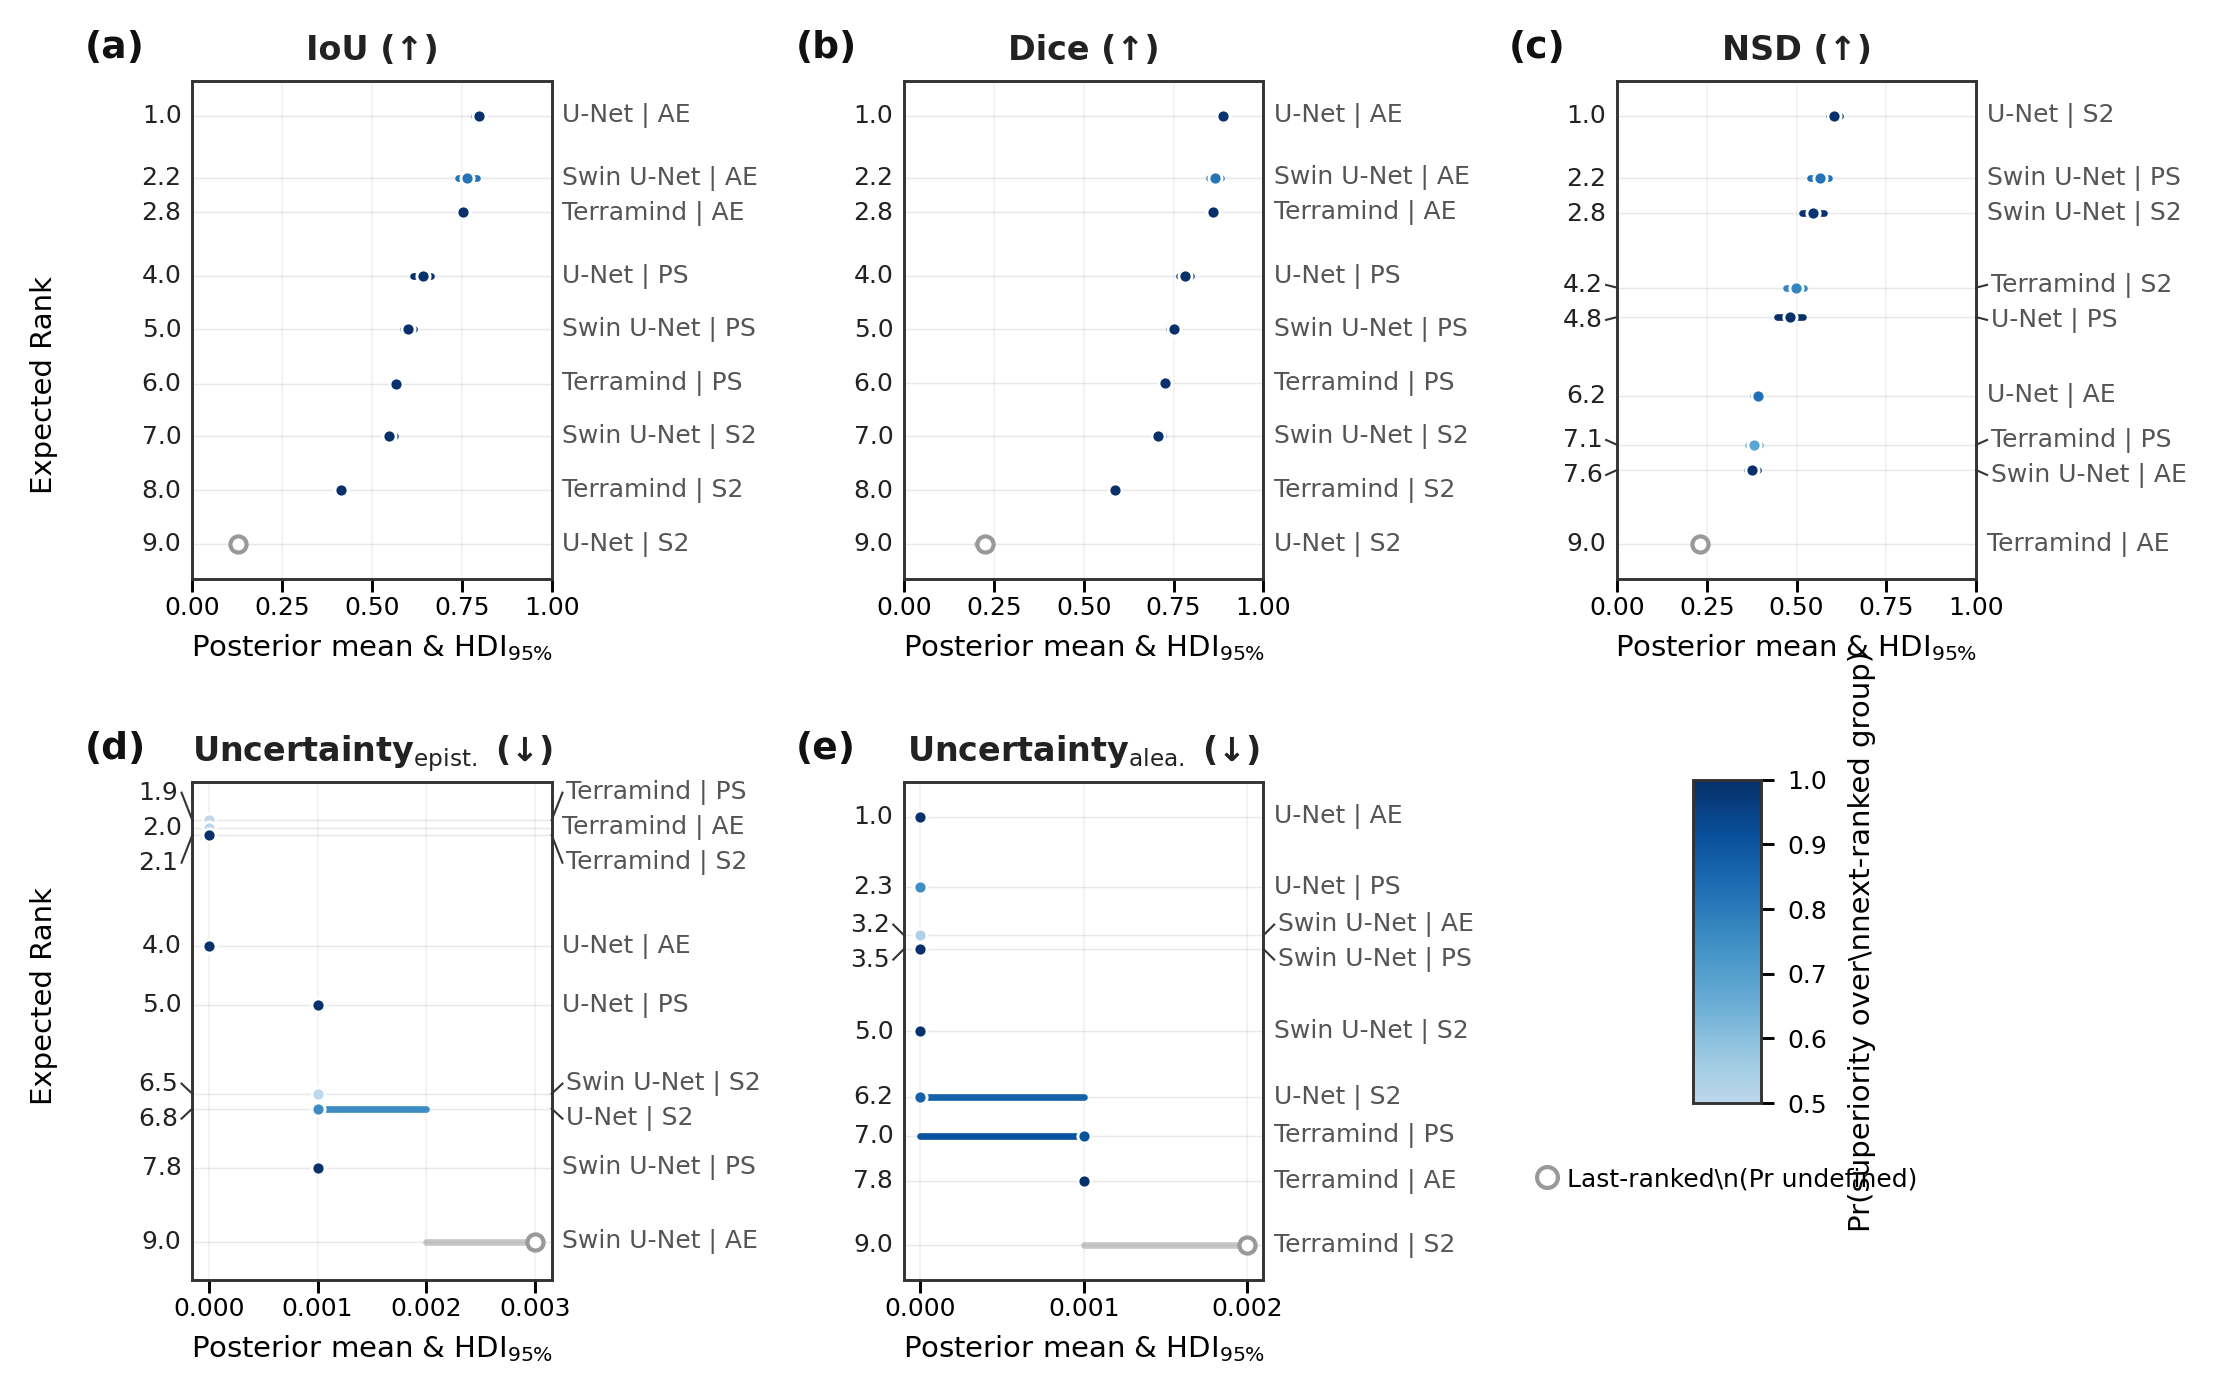

In [125]:
"""
Figure replacing Table 1: Posterior performance, expected rank, and
probability of superiority over next-ranked group for each
sensor–architecture combination across five evaluation metrics.

Changes in this version
────────────────────────
1. Panel labels (a)–(e): placed ABOVE the axes frame, flush-left (outside)
2. Colormap: truncated single-hue Blues — light (uncertain, 0.5) → dark (certain, 1.0)
3. Colorbar + legend: cleanly separated into upper / lower regions of the
   empty 6th slot, with the legend as a dedicated axis so it never overlaps
   the colorbar or its label
"""

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.transforms import blended_transform_factory
from matplotlib.lines import Line2D

# ── Publication rcParams ──────────────────────────────────────────────────────
mpl.rcParams.update({
    "font.size":          7,
    "axes.titlesize":     8,
    "axes.labelsize":     7,
    "xtick.labelsize":    6,
    "ytick.labelsize":    6.5,
    "axes.linewidth":     0.7,
    "xtick.major.width":  0.7,
    "ytick.major.width":  0.7,
    "xtick.major.size":   3,
    "ytick.major.size":   3,
    "pdf.fonttype":       42,
    "ps.fonttype":        42,
    "figure.facecolor":   "white",
    "axes.facecolor":     "white",
})

# ── Load data ─────────────────────────────────────────────────────────────────
COLS = ["group", "mean", "hdi_2.5%", "hdi_97.5%", "E[rank]", "metric", "Pr_sup"]
df = pd.read_csv('./out/Table_1_data.csv', sep=";")[COLS]

# ── Constants ─────────────────────────────────────────────────────────────────
metrics_to_plot = ['IoU', 'Dice', 'NSD', 'epistemic', 'aleatoric']

METRIC_HEADINGS = {
    'IoU':       'IoU (↑)',
    'Dice':      'Dice (↑)',
    'NSD':       'NSD (↑)',
    'epistemic': r'Uncertainty$_\mathrm{epist.}$ (↓)',
    'aleatoric': r'Uncertainty$_\mathrm{alea.}$ (↓)',
}
PANEL_LABELS        = ['(a)', '(b)', '(c)', '(d)', '(e)']
UNCERTAINTY_METRICS = {'epistemic', 'aleatoric'}
SPINE_COLOR         = "#333333"

# Probability of superiority: fixed theoretical range [0.5, 1.0]
PR_VMIN, PR_VMAX = 0.5, 1.0
LAST_RANK_COLOR  = "#999999"   # undefined (last-ranked) group

# ── Colormap ──────────────────────────────────────────────────────────────────
# Truncated Blues: skip the near-white bottom quarter so even Pr=0.5 is
# visibly blue and separable from the white plot background.
_base   = mpl.colormaps['Blues']
pr_cmap = mpl.colors.LinearSegmentedColormap.from_list(
    'pr_sup', [_base(v) for v in np.linspace(0.28, 1.0, 256)], N=256
)
pr_norm = mpl.colors.Normalize(vmin=PR_VMIN, vmax=PR_VMAX)

# ── Figure geometry ───────────────────────────────────────────────────────────
FIG_W_CM    = 18.0
ITEM_H_CM   = 0.55
MIN_PANEL_H = 2.5

def panel_height(n_items):
    return max(MIN_PANEL_H, n_items * ITEM_H_CM)

n_items_row0 = max(len(df[df['metric'] == m]) for m in metrics_to_plot[:3])
n_items_row1 = max(len(df[df['metric'] == m]) for m in metrics_to_plot[3:])
PLOT_W_CM    = (FIG_W_CM - 1.8) / 3

h_row = [
    max(panel_height(n_items_row0), PLOT_W_CM / 2.0),
    max(panel_height(n_items_row1), PLOT_W_CM / 2.0),
]

FIG_H_CM = sum(h_row) + 0.6 + 0.5 + 0.5

# ── Callout helpers ───────────────────────────────────────────────────────────
def spread_y_positions(y_data, min_gap):
    """Push overlapping label positions apart while preserving order."""
    pairs   = sorted(enumerate(y_data), key=lambda p: p[1])
    indices = [p[0] for p in pairs]
    pos     = [p[1] for p in pairs]
    for _ in range(500):
        moved = False
        for i in range(1, len(pos)):
            if pos[i] - pos[i - 1] < min_gap:
                mid         = (pos[i] + pos[i - 1]) / 2.0
                pos[i - 1] = mid - min_gap / 2.0
                pos[i]     = mid + min_gap / 2.0
                moved = True
        if not moved:
            break
    result = [0.0] * len(y_data)
    for sort_i, orig_i in enumerate(indices):
        result[orig_i] = pos[sort_i]
    return result


def apply_side_callouts(ax, y_data, labels, fig_dpi, fontsize=6.5, side='left', color='#222222'):
    ax_h_in   = ax.get_window_extent().height / fig_dpi
    y_range   = abs(ax.get_ylim()[1] - ax.get_ylim()[0])
    line_h_in = fontsize * 1.4 / 72.0
    gap       = (line_h_in / ax_h_in) * y_range if ax_h_in > 0 else 0.5

    y_spread = spread_y_positions(list(y_data), gap)
    trans    = blended_transform_factory(ax.transAxes, ax.transData)

    if side == 'left':
        x0, x1              = 0.0,   -0.03
        xt_moved, xt_nomove = -0.04, -0.03
        ha = 'right'
    else:
        x0, x1              = 1.0,   1.03
        xt_moved, xt_nomove =  1.04,  1.03
        ha = 'left'

    for y_act, y_lbl, label in zip(y_data, y_spread, labels):
        moved = abs(y_act - y_lbl) > gap * 0.05
        if moved:
            ax.plot([x0, x1], [y_act, y_lbl],
                    color='#333333', lw=0.5, clip_on=False,
                    transform=trans, zorder=5)
        ax.text(xt_moved if moved else xt_nomove, y_lbl, label,
                ha=ha, va='center', fontsize=fontsize, color=color,
                transform=trans, clip_on=False)


# ── Build figure ──────────────────────────────────────────────────────────────
fig = plt.figure(
    figsize=(FIG_W_CM / 2.54, FIG_H_CM / 2.54),
    dpi=300,
    constrained_layout=True,
)
fig.set_constrained_layout_pads(
    hspace=0.1,
    wspace=0.1,
    h_pad=0.04,
    w_pad=0.04,
)
gs = GridSpec(2, 6, figure=fig, height_ratios=[h_row[0], h_row[1]])

ax_slots = [
    fig.add_subplot(gs[0, 0:2]),
    fig.add_subplot(gs[0, 2:4]),
    fig.add_subplot(gs[0, 4:6]),
    fig.add_subplot(gs[1, 0:2]),
    fig.add_subplot(gs[1, 2:4]),
]

axes_callout_data = []

for col_idx, (ax, metric) in enumerate(zip(ax_slots, metrics_to_plot)):
    df_m    = df[df['metric'] == metric].sort_values('E[rank]').copy()
    x       = df_m['mean'].values
    y       = df_m['E[rank]'].values
    pr_vals = df_m['Pr_sup'].values
    n       = len(df_m)

    for spine in ['top', 'right', 'left', 'bottom']:
        ax.spines[spine].set_linewidth(0.7)
        ax.spines[spine].set_color(SPINE_COLOR)

    for yp in y:
        ax.axhline(yp, color="#E8E8E8", linewidth=0.35, zorder=0)

    # HDI bars coloured by Pr_sup
    for i in range(n):
        pr_val    = pr_vals[i]
        is_nan    = np.isnan(pr_val)
        bar_color = LAST_RANK_COLOR if is_nan else pr_cmap(pr_norm(pr_val))
        bar_alpha = 0.55 if is_nan else 1.0
        lc = ax.hlines(
            y     = df_m['E[rank]'].iloc[i],
            xmin  = df_m['hdi_2.5%'].iloc[i],
            xmax  = df_m['hdi_97.5%'].iloc[i],
            color = bar_color,
            lw    = 1.6,
            alpha = bar_alpha,
            zorder= 2,
        )
        lc.set_capstyle('round')

    # Mean dots: open grey circle for last-ranked, coloured fill for others
    for i in range(n):
        pr_val = pr_vals[i]
        if np.isnan(pr_val):
            ax.scatter(x[i], y[i], s=15, marker='o',
                       facecolors='white', edgecolors=LAST_RANK_COLOR,
                       linewidths=1.0, zorder=4)
        else:
            ax.scatter(x[i], y[i], s=10, marker='o',
                       c=[pr_val], cmap=pr_cmap, norm=pr_norm,
                       edgecolors='white', linewidths=0.7, zorder=3)

    ax.grid(axis='x', alpha=0.18, linewidth=0.4, zorder=0)
    ax.set_axisbelow(True)
    ax.set_yticks(y.tolist())
    ax.set_yticklabels([])
    ax.tick_params(axis='y', length=0, pad=0)

    ax.set_title(METRIC_HEADINGS[metric],
                 fontsize=8, fontweight='bold', pad=5, color='#222222')
    ax.set_xlabel(r'Posterior mean & HDI$_{95\%}$', fontsize=7, labelpad=3)
    ax.tick_params(axis='x', labelsize=6, length=3, width=0.7, pad=1)

    if metric not in UNCERTAINTY_METRICS:
        ax.set_xlim(0, 1)

    ax.set_ylim(y.min() - 0.65, y.max() + 0.65)
    ax.invert_yaxis()

    # ── Panel label: OUTSIDE the frame, above the top-left corner ─────────
    # x=0.0  → flush with the left edge of the axes frame
    # y=1.03 → 3% above the top of the axes frame (outside, never overlapping)
    # va='bottom' anchors the text above the y position (won't drop into frame)
    ax.text(
        -0.3, 1.03, PANEL_LABELS[col_idx],
        transform  = ax.transAxes,
        fontsize   = 9,
        fontweight = 'bold',
        va         = 'bottom',
        ha         = 'left',
        color      = '#111111',
        clip_on    = False,
    )

    axes_callout_data.append((ax, y.tolist(), df_m['group'].tolist()))


# ── Canvas draw — triggers constrained_layout geometry ───────────────────────
fig.canvas.draw()

# ── Second pass: callouts (need rendered axes heights) ────────────────────────
for ax, y_data, labels in axes_callout_data:
    rank_labels = [f"{v:.1f}" for v in y_data]
    apply_side_callouts(ax, y_data, rank_labels, fig.dpi, fontsize=6.0, side='left')
    apply_side_callouts(ax, y_data, labels, fig.dpi, fontsize=6.0, side='right', color='#555555')

# ── Shared y-axis labels ──────────────────────────────────────────────────────
fig.text(-0.02, 0.73, 'Expected Rank',
         va='center', ha='left', rotation=90, fontsize=7)
fig.text(-0.02, 0.28, 'Expected Rank',
         va='center', ha='left', rotation=90, fontsize=7)


# ── Colorbar + legend in the empty 6th slot ──────────────────────────────────
# Layout within the slot (fractions of slot height, measured from bottom):
#   0.00–0.20  →  legend axes
#   0.20–0.26  →  gap
#   0.26–0.94  →  colorbar
#   0.94–1.00  →  top breathing room

tmp_ax = fig.add_subplot(gs[1, 4:6])
slot   = tmp_ax.get_position()   # Bbox in figure coords
tmp_ax.remove()

# Colorbar
cbar_w = slot.width * 0.13
cbar_h = slot.height * 0.68
cbar_x = slot.x0 + (slot.width - cbar_w) / 2.0
cbar_y = slot.y0 + slot.height * 0.26

cax = fig.add_axes([cbar_x, cbar_y, cbar_w, cbar_h])

sm = mpl.cm.ScalarMappable(norm=pr_norm, cmap=pr_cmap)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cax, orientation='vertical')
cbar.set_label(
    'Pr(superiority over\\nnext-ranked group)',
    fontsize=7, labelpad=5,
)
cbar.set_ticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
cbar.ax.tick_params(labelsize=6, width=0.7, length=3)
for spine in cax.spines.values():
    spine.set_linewidth(0.7)
    spine.set_edgecolor(SPINE_COLOR)

# Legend: dedicated axis in the lower 20% of the slot
leg_ax = fig.add_axes([slot.x0, slot.y0, slot.width, slot.height * 0.20])
leg_ax.set_axis_off()

grey_entry = Line2D(
    [0], [0],
    marker          = 'o',
    color           = 'none',
    markerfacecolor = 'white',
    markeredgecolor = LAST_RANK_COLOR,
    markeredgewidth = 1.0,
    markersize      = 5,
    label           = 'Last-ranked\\n(Pr undefined)',
)
leg_ax.legend(
    handles       = [grey_entry],
    loc           = 'center',
    fontsize      = 6,
    frameon       = False,
    framealpha    = 0.9,
    edgecolor     = '#CCCCCC',
    handlelength  = 0.8,
    handletextpad = 0.4,
    borderpad     = 0.6,
)

# ── Save ──────────────────────────────────────────────────────────────────────
plt.savefig('./out/figure_table1_replacement.pdf', bbox_inches='tight', dpi=300)
plt.savefig('./out/figure_table1_replacement.png', bbox_inches='tight', dpi=300)
plt.show()